In [29]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm
from sklearn.metrics import pairwise_distances

import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
path = '../MEC_02_115/Raw Data/'
dirs = os.listdir(path)
#del dirs[1]
dirs

['MF_L_01',
 'CR_N_01',
 'KC_L_02',
 'FB_L_01',
 '.DS_Store',
 'FB_N_02',
 'KC_N_01',
 'LDPE_1to4micron_20240423.ptir',
 'MF_N_02',
 'Blank_02',
 'KC_L_01',
 'CR_N_02',
 'MF_L_02',
 'FB_L_02',
 'FB_N_01',
 'MF_N_01',
 'Blank_01',
 'KC_N_02',
 'mgstearate_20240409.ptir']

In [31]:
'.DS_Store'[-4:]

'tore'

In [32]:
dirs_2 = []
for d in dirs:
    if d[-4:] == 'ptir' or d == '.DS_Store':
        continue
    d_2 = os.listdir(path + d)
    #dirs_2 = dirs_2 + [d+'/'+f for f in d_2 if f[:6] == 'Mosaic'] Mosaic
    dirs_2 = dirs_2 + [d+'/'+f for f in d_2 if 'Mosaic' in f and 'ptir' not in f]
dirs_2

['MF_L_01/Mosaic 2',
 'MF_L_01/Mosaic 5',
 'MF_L_01/Mosaic 3',
 'MF_L_01/Additional Mosaics',
 'MF_L_01/Mosaic 1',
 'CR_N_01/Mosaic 7 (20240319)',
 'CR_N_01/Mosaic 5 (20240319)',
 'CR_N_01/Additional Mosaics',
 'CR_N_01/Mosaic 6 (20240319)',
 'KC_L_02/Mosaic 2',
 'KC_L_02/Mosaic 3',
 'KC_L_02/Additional Mosaics',
 'KC_L_02/Mosaic 1',
 'FB_L_01/Mosaic 4',
 'FB_L_01/Mosaic 3',
 'FB_L_01/Additional Mosaics',
 'FB_L_01/Mosaic 1',
 'FB_N_02/Additional Mosaics for Optical Analysis',
 'FB_N_02/Mosaic 2',
 'FB_N_02/Mosaic 3',
 'FB_N_02/Mosaic 1',
 'KC_N_01/Mosaic 3 (20240321)',
 'KC_N_01/Mosaic 1 (20240321)',
 'KC_N_01/Mosaic 2 (20240321)',
 'KC_N_01/Additional Mosaics',
 'MF_N_02/Mosaic 2',
 'MF_N_02/Mosaic 5',
 'MF_N_02/Additional Mosaics',
 'MF_N_02/Mosaic 6',
 'MF_N_02/Mosaic 1',
 'Blank_02/Mosaic 2',
 'Blank_02/Mosaic 4',
 'Blank_02/Mosaic 3',
 'Blank_02/Mosaic 1',
 'KC_L_01/Mosaic 2',
 'KC_L_01/Mosaic 3',
 'KC_L_01/Additional Mosaics',
 'KC_L_01/Mosaic 1',
 'CR_N_02/Mosaic 1 (20240326)',

In [33]:
files_list = []
for d in dirs_2:
    files = os.listdir(path + d)
    files_list = files_list + [d+'/'+f for f in files if f[-4:] == '.csv']

In [34]:
#files_list = [x for x in files_list if 'FF_FOV' not in x]

In [35]:
np.unique([str(x[5:7]) if x[5] == "0" else str(x[6:8]) for x in files_list])

array(['01', '02'], dtype='<U2')

In [36]:
[len(x)  for x in files_list]

[59,
 58,
 59,
 59,
 59,
 42,
 42,
 42,
 42,
 42,
 59,
 59,
 59,
 42,
 59,
 59,
 59,
 59,
 58,
 42,
 58,
 42,
 59,
 42,
 59,
 59,
 42,
 58,
 42,
 42,
 60,
 60,
 42,
 42,
 42,
 59,
 59,
 59,
 59,
 60,
 59,
 59,
 60,
 59,
 59,
 59,
 59,
 59,
 42,
 42,
 59,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 42,
 42,
 42,
 59,
 59,
 59,
 59,
 42,
 69,
 71,
 53,
 53,
 53,
 53,
 53,
 70,
 71,
 70,
 69,
 70,
 70,
 53,
 53,
 53,
 53,
 53,
 53,
 53,
 53,
 70,
 69,
 52,
 52,
 52,
 53,
 52,
 53,
 53,
 52,
 53,
 53,
 53,
 52,
 52,
 53,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 53,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 52,
 70,
 70,
 53,
 71,
 69,
 53,
 53,
 53,
 70,
 53,
 53,
 53,
 60,
 42,
 42,
 42,
 42,
 42,
 42,
 42,
 42,
 42,
 60,
 59,
 42,
 42,
 60,
 42,
 42,
 42,
 42,
 42,
 42,
 42,
 60,
 52,
 53,
 52,
 52,
 52,
 52,
 53,
 52,
 53,
 52,
 52,
 52,
 52,
 52,
 52,
 53,
 52,
 53,


In [37]:
np.unique([str(x[:2]) for x in files_list])

array(['Bl', 'CR', 'FB', 'KC', 'MF'], dtype='<U2')

In [38]:
np.unique([str(x[8:16]) if x[7] == '/' else 
                                               str(x[9:17]) for x in files_list])

array(['Addition', 'Mosaic 1', 'Mosaic 2', 'Mosaic 3', 'Mosaic 4',
       'Mosaic 5', 'Mosaic 6', 'Mosaic 7', 'Mosaic 9'], dtype='<U8')

In [39]:
mosaics_ = [str(x[8:16]) if x[7] == '/' else str(x[9:17]) for x in files_list]

#[y for x, y in zip(mosaics_, files_list) if x =="Addition"]
np.unique([str(x[3:4]) if str(x[:2]) != "Bl" else "-" for x in files_list])

array(['-', 'L', 'N'], dtype='<U1')

In [41]:
files_codes = pd.merge(pd.DataFrame({'file_name':files_list,
                                     'key':[str(x[:2]) for x in files_list],
                                     'run':[str(x[5:7]) if x[5] == "0" else 
                                            str(x[6:8]) for x in files_list],
                                     'mosaic':[str(x[8:16]) if x[7] == '/' else 
                                               str(x[9:17]) for x in files_list],
                                     'material':[str(x[3:4]) if str(x[:2]) != "Bl" 
                                                 else "-" for x in files_list]}),
                       pd.DataFrame({'key':np.unique([str(x[:2]) for x in files_list]),
                                     'brand':['Blank','CR', 'FB', 'KC', 'MF']}))
                                     #'brand':['CR', 'FB', 'KC', 'MF']}))
files_codes = files_codes.set_index('file_name')
files_codes

,key,run,mosaic,material,brand
file_name,,,,,
MF_L_01/Mosaic 2/MF_L_01_40Xmosaic_2_FF_FOV7_1particles.csv,MF,01,Mosaic 2,L,MF
MF_L_01/Mosaic 2/MF_L_01_40Xmosaic_2_FF_FOV3_1particle.csv,MF,01,Mosaic 2,L,MF
MF_L_01/Mosaic 2/MF_L_01_40Xmosaic_2_FF_FOV1_1particles.csv,MF,01,Mosaic 2,L,MF
MF_L_01/Mosaic 2/MF_L_01_40Xmosaic_2_FF_FOV11_1particle.csv,MF,01,Mosaic 2,L,MF
MF_L_01/Mosaic 2/MF_L_01_40Xmosaic_2_FF_FOV6_1particles.csv,MF,01,Mosaic 2,L,MF
...,...,...,...,...,...
Blank_01/Mosaic 1/Blank__01_40Xmosaic_1_FF_FOV1_2particles.csv,Bl,01,Mosaic 1,-,Blank
Blank_01/Mosaic 1/Blank__01_40Xmosaic_1_FF_FOV3_1particles.csv,Bl,01,Mosaic 1,-,Blank
Blank_01/Mosaic 1/Blank__01_40Xmosaic_1_FF_FOV4_1particles.csv,Bl,01,Mosaic 1,-,Blank


In [42]:
np.sum(["FOV" in x for x in files_codes.index])

254

In [43]:
df_list = []
prev_mosaic = ''
count = 1
for f in files_list:
    df = pd.read_csv(path + f)
    df.columns = ['feat_id', 'map_x', 'map_y', 'size', 'area', 'perimeter', 'circularity']
    mosaic = files_codes.loc[f, 'mosaic']
    if mosaic == prev_mosaic:
        count = count + 1
    df['id'] = [files_codes.loc[f, 'brand'] + '_' + 
                files_codes.loc[f, 'material'] + '_' + 
                files_codes.loc[f, 'run'] + '_' + 
                files_codes.loc[f, 'mosaic'] + '_' +
                str(count) + '_' +
                str(i + 1) for i in range(df.shape[0])]
    
    df['id_file'] = [files_codes.loc[f, 'brand'] + '_' + 
                files_codes.loc[f, 'material'] + '_' + 
                files_codes.loc[f, 'run'] for i in range(df.shape[0])]
    
    #df['brand'] = files_codes.loc[f, 'brand']
    #df['run'] = files_codes.loc[f, 'run']
    #df['mosaic'] = files_codes.loc[f, 'mosaic']
    df_list.append(df.iloc[:,1:])
    prev_mosaic = mosaic
    
coord_df = pd.concat(df_list,axis=0)

In [2]:
#coord_df#.groupby('id_file').count()

In [45]:
coord_df.to_csv('particle_info_all.csv')

In [44]:
coord_df#.count()

,map_x,map_y,size,area,perimeter,circularity,id,id_file
0,17174.310,3375.7600,2.255220,3.844700,7.785713,0.796721,MF_L_01_Mosaic 2_1_1,MF_L_01
0,17644.230,3377.4460,5.163274,20.791040,17.853720,0.819331,MF_L_01_Mosaic 2_2_1,MF_L_01
0,17659.150,3248.0210,0.565554,0.254195,2.145605,0.693599,MF_L_01_Mosaic 2_3_1,MF_L_01
1,17659.320,3248.1130,5.939337,27.755980,22.678630,0.677897,MF_L_01_Mosaic 2_3_2,MF_L_01
0,17210.770,3233.8040,1.319911,1.292158,4.452943,0.818582,MF_L_01_Mosaic 2_4_1,MF_L_01
...,...,...,...,...,...,...,...,...
12,-7212.583,1021.7010,1.164607,1.084566,4.161057,0.786845,KC_N_02_Mosaic 2_1326_13,KC_N_02
13,-7241.096,1024.4880,1.088929,0.955350,4.015114,0.744402,KC_N_02_Mosaic 2_1326_14,KC_N_02
0,-7509.832,802.4348,0.967744,0.735047,3.256528,0.870656,KC_N_02_Mosaic 2_1327_1,KC_N_02
1,-7505.213,810.0744,1.641002,2.156421,5.494165,0.897369,KC_N_02_Mosaic 2_1327_2,KC_N_02


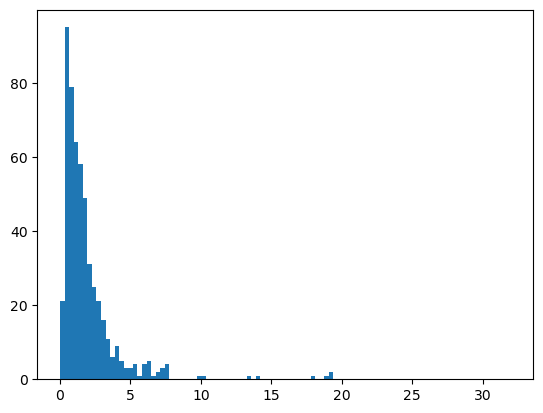

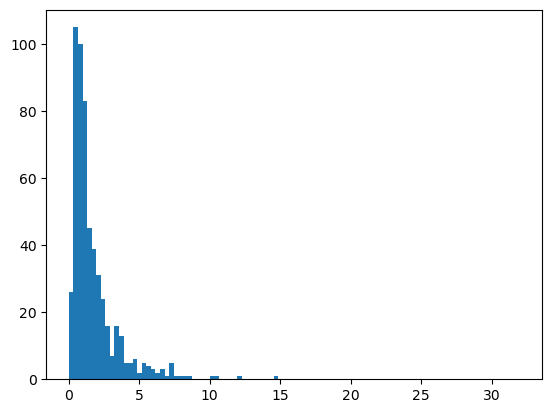

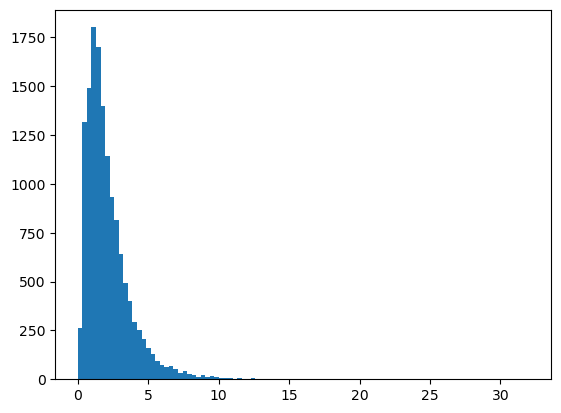

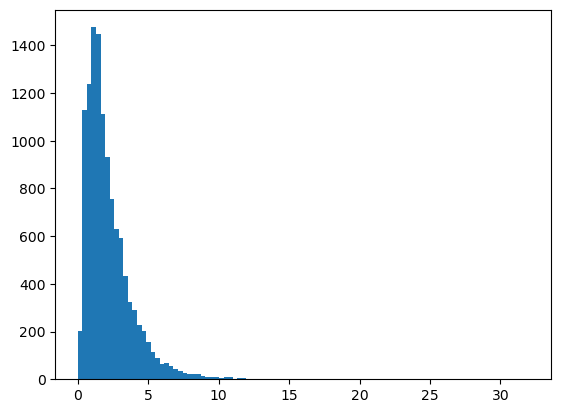

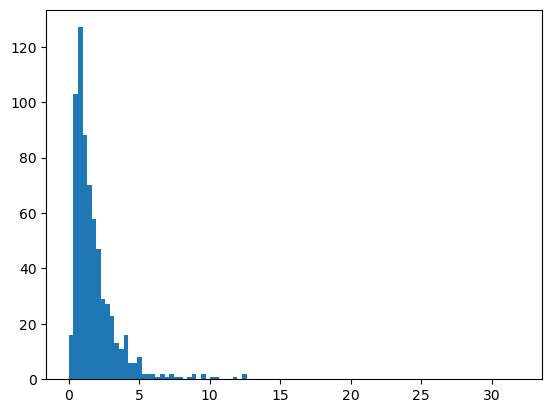

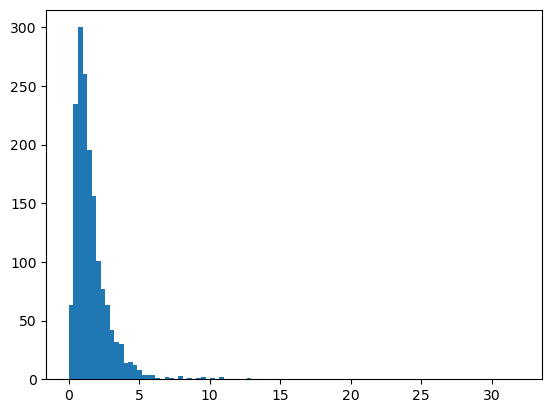

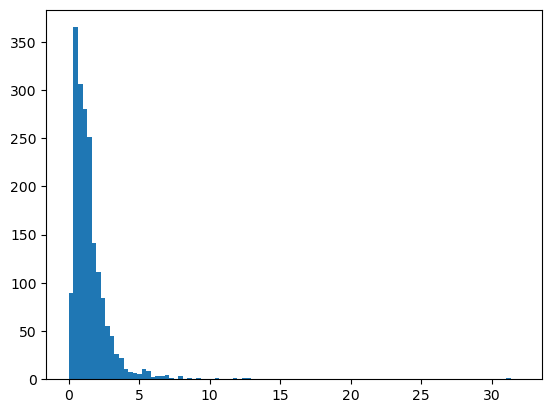

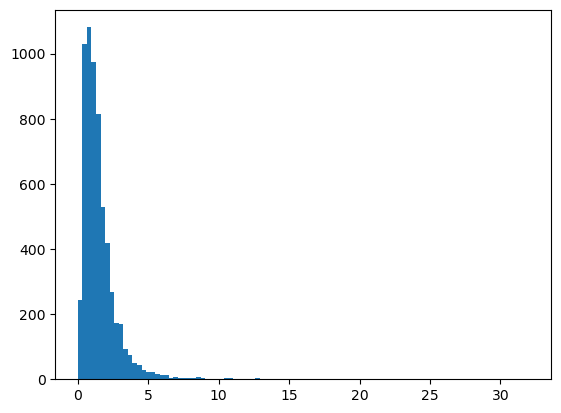

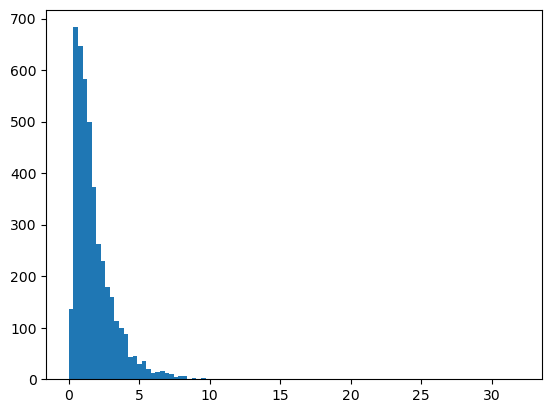

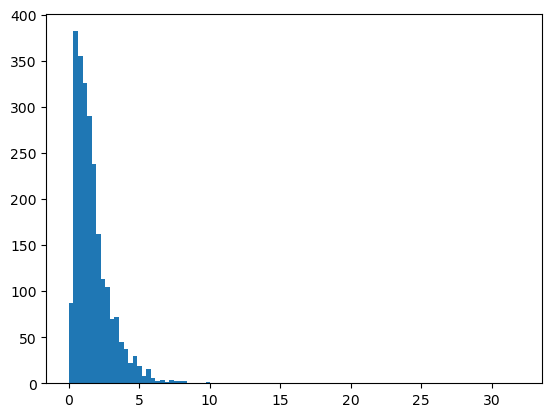

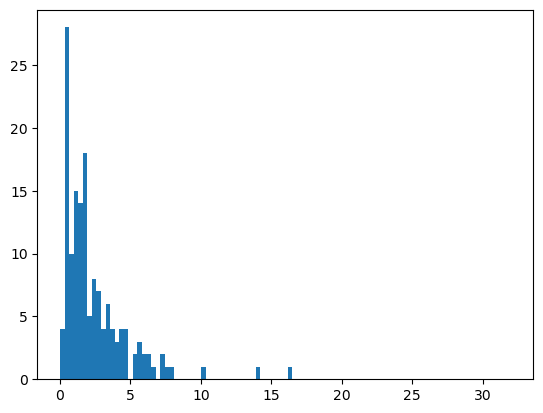

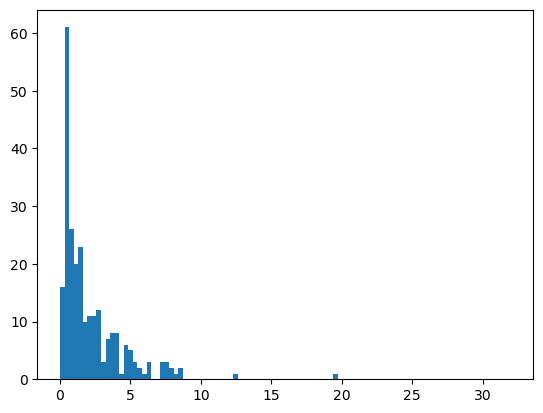

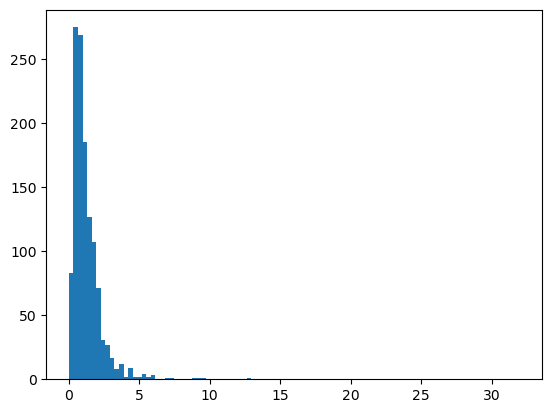

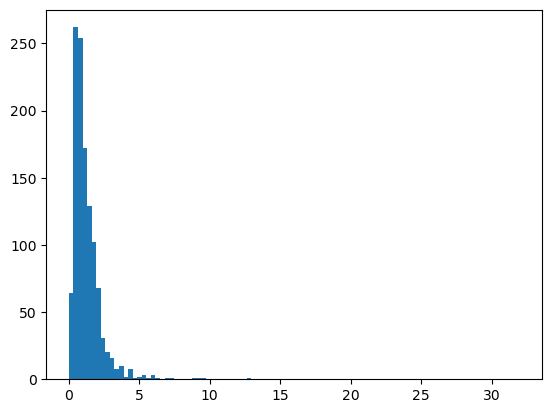

In [15]:
hist_list = []
for subs in np.unique(coord_df['id_file']):
    hist_part = plt.hist(coord_df.query('id_file == @subs').loc[:,['size']], bins = np.linspace(0,32,100))
    hist_list.append(hist_part[0][:,None])
    _ = plt.show()

In [92]:
part_size_distr = pd.DataFrame(np.concatenate([np.linspace(0,32,100)[1:,None]]+hist_list, axis=1))
part_size_distr.columns = ['size'] + list(np.unique(coord_df['id_file']))
part_size_distr.to_csv('particle_size_distr.csv')#.sum()
part_size_distr.set_index('size')

,CR_N_01,CR_N_02,FB_L_01,FB_L_02,FB_N_01,FB_N_02,KC_L_01,KC_L_02,KC_N_01,KC_N_02,MF_L_01,MF_L_02,MF_N_01,MF_N_02
size,,,,,,,,,,,,,,
0.323232,21.0,26.0,262.0,202.0,16.0,63.0,89.0,243.0,136.0,87.0,4.0,16.0,83.0,64.0
0.646465,95.0,105.0,1319.0,1129.0,103.0,235.0,365.0,1031.0,683.0,382.0,28.0,61.0,275.0,262.0
0.969697,79.0,100.0,1492.0,1240.0,127.0,300.0,306.0,1081.0,646.0,355.0,10.0,26.0,269.0,254.0
1.292929,64.0,83.0,1802.0,1476.0,88.0,260.0,280.0,975.0,583.0,326.0,15.0,20.0,185.0,172.0
1.616162,58.0,45.0,1703.0,1447.0,70.0,195.0,251.0,815.0,499.0,290.0,14.0,23.0,127.0,129.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30.707071,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31.030303,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
31.353535,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
#spectra_data_raman = pd.read_csv('data_raman.csv')
spectra_data_raman = pd.read_csv('data_raman_new.csv')
del spectra_data_raman['Unnamed: 0']
#spectra_data_raman['id_file'] = spectra_data_raman['brand'] +"_"+ spectra_data_raman['material'] +"_0"+ spectra_data_raman['run'].astype('str')  #.loc[:,['map_x', 'map_y']]
spectra_data_raman['id_file'] = [x[:7] if x[0] !='B' else x[:10] for x in spectra_data_raman['id']] 
spectra_data_raman

,355.5555419921875,357.72357177734375,359.8915710449219,362.0596008300781,364.2276306152344,366.3956604003906,368.56365966796875,370.731689453125,372.89971923828125,375.0677490234375,...,3885.0947265625,3887.262939453125,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x,map_y,id,id_file
0,-0.213909,-0.222695,-0.223055,-0.229050,-0.239413,-0.252912,-0.265272,-0.275395,-0.297114,-0.313945,...,0.026856,0.026856,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01
1,-1.065365,-1.199256,-1.291840,-1.357812,-1.403152,-1.433264,-1.494057,-1.610283,-1.732304,-1.820711,...,0.031343,0.031343,0.031343,0.031343,0.031343,0.031343,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01
2,0.284673,0.462057,0.570947,0.599476,0.565704,0.460668,0.363080,0.283669,0.348939,0.455903,...,3.563695,3.563695,3.563695,3.563695,3.563695,3.563695,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01
3,-0.303571,-0.296946,-0.286365,-0.285138,-0.291161,-0.295581,-0.293379,-0.279556,-0.273223,-0.267543,...,1.268223,1.268223,1.268223,1.268223,1.268223,1.268223,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01
4,-0.077380,-0.055953,-0.003824,-0.002065,-0.039354,-0.124050,-0.203422,-0.270050,-0.263790,-0.225598,...,-0.654808,-0.654808,-0.654808,-0.654808,-0.654808,-0.654808,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,0.383753,0.377265,0.389140,0.399228,0.407930,0.386511,0.378929,0.397973,0.387454,0.366135,...,-0.228953,-0.228953,-0.228953,-0.228953,-0.228953,-0.228953,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02
1482,1.931624,1.919164,1.922414,1.918872,1.910065,1.855714,1.823330,1.833057,1.818470,1.791681,...,-0.382997,-0.382997,-0.382997,-0.382997,-0.382997,-0.382997,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02
1483,0.686006,0.787111,0.780688,0.735241,0.659540,0.625907,0.610585,0.624770,0.579044,0.515131,...,2.389990,2.389990,2.389990,2.389990,2.389990,2.389990,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02
1484,-0.056562,-0.074897,-0.070449,-0.063122,-0.053563,-0.070849,-0.080261,-0.073842,-0.068661,-0.064382,...,-0.264897,-0.264897,-0.264897,-0.264897,-0.264897,-0.264897,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02


In [74]:
np.argsort(pairwise_distances(spectra_data_raman.loc[:,['map_x', 'map_y']], 
                                          coord_df.loc[:,['map_x', 'map_y']]), axis=1)

(1486, 14347)

(1481,)

In [64]:
id_matches = np.argmin(pairwise_distances(spectra_data_raman.loc[:,['map_x', 'map_y']], 
                                          coord_df.loc[:,['map_x', 'map_y']]),1)
coord_matches = coord_df.iloc[id_matches, :].reset_index(drop=True)
spectra_matches = spectra_data_raman.merge(coord_matches, on='id_file', how='left').iloc[:, -15:]
spectra_matches

,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x_x,map_y_x,id_x,id_file,map_x_y,map_y_y,size,area,perimeter,circularity,id_y
0,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15624.560,1545.174,1.836663,2.633419,6.703690,0.736140,MF_L_01_Mosaic 1_56_1
1,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15623.290,1550.499,0.651304,0.302916,2.497942,0.609815,MF_L_01_Mosaic 1_53_2
2,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15617.680,1564.703,1.388501,1.506106,5.563866,0.611143,MF_L_01_Mosaic 1_53_3
3,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15620.600,1565.341,1.632973,1.673451,6.535387,0.492165,MF_L_01_Mosaic 1_53_4
4,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15616.280,1570.091,0.636946,0.275378,2.199516,0.715016,MF_L_01_Mosaic 1_53_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150205,-0.348001,-0.348001,-0.348001,-0.348001,-4507.250000,-1741.550049,KC_N_02_0328_32,KC_N_02,-4543.314,-1760.015,1.422096,1.533643,4.995885,0.771863,KC_N_02_Mosaic 1_546_7
150206,-0.348001,-0.348001,-0.348001,-0.348001,-4507.250000,-1741.550049,KC_N_02_0328_32,KC_N_02,-4501.917,-1758.334,1.331205,1.357825,4.697458,0.772963,KC_N_02_Mosaic 1_546_8
150207,-0.348001,-0.348001,-0.348001,-0.348001,-4507.250000,-1741.550049,KC_N_02_0328_32,KC_N_02,-4510.644,-1747.328,0.694288,0.379174,2.628095,0.689600,KC_N_02_Mosaic 1_546_9
150208,-0.348001,-0.348001,-0.348001,-0.348001,-4507.250000,-1741.550049,KC_N_02_0328_32,KC_N_02,-4511.191,-1743.359,2.594529,5.022470,9.855076,0.649588,KC_N_02_Mosaic 1_546_10


In [65]:
id_matches = np.argmin(pairwise_distances(spectra_data_raman.loc[:,['map_x', 'map_y']], 
                                          coord_df.loc[:,['map_x', 'map_y']]),1)

coord_matches = coord_df.iloc[id_matches, :].reset_index(drop=True)
spectra_matches = spectra_data_raman.merge(coord_matches, left_index=True, right_index=True).iloc[:, -16:]
spectra_matches['distance'] = np.sqrt((spectra_matches['map_x_x'] - spectra_matches['map_x_y']) ** 2 + 
 (spectra_matches['map_y_x'] - spectra_matches['map_y_y']) ** 2)
spectra_matches

,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x_x,map_y_x,id_x,id_file_x,map_x_y,map_y_y,size,area,perimeter,circularity,id_y,id_file_y,distance
0,0.026856,0.026856,0.026856,0.026856,15624.450195,1545.449951,MF_L_01_0514_1,MF_L_01,15624.560,1545.174,1.836663,2.633419,6.703690,0.736140,MF_L_01_Mosaic 1_56_1,MF_L_01,0.296995
1,0.031343,0.031343,0.031343,0.031343,15623.299805,1550.750000,MF_L_01_0514_2,MF_L_01,15623.290,1550.499,0.651304,0.302916,2.497942,0.609815,MF_L_01_Mosaic 1_53_2,MF_L_01,0.251191
2,3.563695,3.563695,3.563695,3.563695,15617.500000,1564.949951,MF_L_01_0514_3,MF_L_01,15617.680,1564.703,1.388501,1.506106,5.563866,0.611143,MF_L_01_Mosaic 1_53_3,MF_L_01,0.305589
3,1.268223,1.268223,1.268223,1.268223,15620.650391,1565.050049,MF_L_01_0514_4,MF_L_01,15620.600,1565.341,1.632973,1.673451,6.535387,0.492165,MF_L_01_Mosaic 1_53_4,MF_L_01,0.295283
4,-0.654808,-0.654808,-0.654808,-0.654808,15616.150391,1570.400024,MF_L_01_0514_5,MF_L_01,15616.280,1570.091,0.636946,0.275378,2.199516,0.715016,MF_L_01_Mosaic 1_53_5,MF_L_01,0.335104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,-0.228953,-0.228953,-0.228953,-0.228953,-4543.500000,-1759.750000,KC_N_02_0328_28,KC_N_02,-4543.314,-1760.015,1.422096,1.533643,4.995885,0.771863,KC_N_02_Mosaic 1_546_7,KC_N_02,0.323761
1482,-0.382997,-0.382997,-0.382997,-0.382997,-4501.899902,-1758.099976,KC_N_02_0328_29,KC_N_02,-4501.917,-1758.334,1.331205,1.357825,4.697458,0.772963,KC_N_02_Mosaic 1_546_8,KC_N_02,0.234648
1483,2.389990,2.389990,2.389990,2.389990,-4510.850098,-1747.099976,KC_N_02_0328_30,KC_N_02,-4510.644,-1747.328,0.694288,0.379174,2.628095,0.689600,KC_N_02_Mosaic 1_546_9,KC_N_02,0.307362
1484,-0.264897,-0.264897,-0.264897,-0.264897,-4511.100098,-1743.050049,KC_N_02_0328_31,KC_N_02,-4511.191,-1743.359,2.594529,5.022470,9.855076,0.649588,KC_N_02_Mosaic 1_546_10,KC_N_02,0.322047


In [28]:
np.where(~np.array(np.array([x[:7] for x in coord_matches['id']]) == coord_matches['id_file']))[0]

array([ 737,  738,  739,  740,  741,  742,  743,  744,  745,  746,  747,
        748,  749,  750,  751,  752,  753,  754,  755,  756,  757,  758,
        759,  760,  761,  762,  763,  764,  765, 1373, 1374, 1375, 1376,
       1377, 1378, 1379, 1380, 1381, 1382, 1383, 1384, 1385])

In [31]:
coord_matches#.iloc[np.where(~np.array(np.array([x[:7] for x in coord_matches['id']]) == coord_matches['id_file']))[0],:]

,map_x,map_y,size,area,perimeter,circularity,id,id_file
0,15624.560,1545.174,1.836663,2.633419,6.703690,0.736140,MF_L_01_Mosaic 1_56_1,MF_L_01
1,15623.290,1550.499,0.651304,0.302916,2.497942,0.609815,MF_L_01_Mosaic 1_53_2,MF_L_01
2,15617.680,1564.703,1.388501,1.506106,5.563866,0.611143,MF_L_01_Mosaic 1_53_3,MF_L_01
3,15620.600,1565.341,1.632973,1.673451,6.535387,0.492165,MF_L_01_Mosaic 1_53_4,MF_L_01
4,15616.280,1570.091,0.636946,0.275378,2.199516,0.715016,MF_L_01_Mosaic 1_53_5,MF_L_01
...,...,...,...,...,...,...,...,...
1481,-4543.314,-1760.015,1.422096,1.533643,4.995885,0.771863,KC_N_02_Mosaic 1_546_7,KC_N_02
1482,-4501.917,-1758.334,1.331205,1.357825,4.697458,0.772963,KC_N_02_Mosaic 1_546_8,KC_N_02
1483,-4510.644,-1747.328,0.694288,0.379174,2.628095,0.689600,KC_N_02_Mosaic 1_546_9,KC_N_02
1484,-4511.191,-1743.359,2.594529,5.022470,9.855076,0.649588,KC_N_02_Mosaic 1_546_10,KC_N_02


In [17]:
for id_ in np.unique(spectra_data_raman['id_file']):
    print(id_, coord_df.query('id_file == @id_').shape)

Blank_-_01 (13, 8)
Blank_-_02 (30, 8)
CR_N_01 (372, 8)
CR_N_02 (428, 8)
FB_L_01 (4060, 8)
FB_L_02 (3251, 8)
FB_N_01 (354, 8)
FB_N_02 (670, 8)
KC_L_01 (880, 8)
KC_L_02 (1061, 8)
KC_N_01 (1540, 8)
KC_N_02 (646, 8)
MF_L_01 (97, 8)
MF_L_02 (106, 8)
MF_N_01 (341, 8)
MF_N_02 (263, 8)


In [18]:
for id_ in np.unique(spectra_data_raman['id_file']):
    print(id_, spectra_data_raman.query('id_file == @id_').shape)

Blank_-_01 (13, 1032)
Blank_-_02 (29, 1032)
CR_N_01 (105, 1032)
CR_N_02 (104, 1032)
FB_L_01 (113, 1032)
FB_L_02 (100, 1032)
FB_N_01 (100, 1032)
FB_N_02 (108, 1032)
KC_L_01 (102, 1032)
KC_L_02 (103, 1032)
KC_N_01 (110, 1032)
KC_N_02 (100, 1032)
MF_L_01 (97, 1032)
MF_L_02 (99, 1032)
MF_N_01 (103, 1032)
MF_N_02 (105, 1032)


In [112]:
for id_ in np.unique(spectra_data_raman['id_file']):
    #id_ = np.unique(spectra_data_raman['id_file'])[2]
    print(id_)
    print(min(np.sum(pairwise_distances(spectra_data_raman.query('id_file == @id_').loc[:,['map_x', 'map_y']], 
                                                  coord_df.query('id_file == @id_').loc[:,['map_x', 'map_y']])<1,1)),
    max(np.sum(pairwise_distances(spectra_data_raman.query('id_file == @id_').loc[:,['map_x', 'map_y']], 
                                                  coord_df.query('id_file == @id_').loc[:,['map_x', 'map_y']])<1,1)))


Blank_-_01
1 1
Blank_-_02
1 2
CR_N_01
1 3
CR_N_02
0 3
FB_L_01
1 4
FB_L_02
1 3
FB_N_01
1 3
FB_N_02
1 3
KC_L_01
1 3
KC_L_02
1 3
KC_N_01
0 3
KC_N_02
0 3
MF_L_01
1 2
MF_L_02
1 3
MF_N_01
1 3
MF_N_02
1 3


In [114]:
np.argsort(pairwise_distances(spectra_data_raman.query('id_file == @id_').loc[:,['map_x', 'map_y']], 
                                                  coord_df.query('id_file == @id_').loc[:,['map_x', 'map_y']]))

array([[188, 227, 229, ..., 185, 142,  88],
       [189, 228, 239, ..., 185, 142,  88],
       [190, 229, 228, ..., 185, 142,  88],
       ...,
       [127, 162, 129, ...,  84,  62,  85],
       [128, 163, 126, ...,  84,  62,  85],
       [129, 164, 162, ...,  84,  62,  85]])

In [90]:
spectra_data_raman.query('id_file == @id_').loc[:,['map_x', 'map_y']]

,map_x,map_y
96,-2968.649902,-2010.150024
97,-2970.300049,-2006.150024
98,-2960.850098,-2002.000000
99,-2946.300049,-1993.800049
100,-2935.000000,-1992.449951
...,...,...
196,411.200012,-886.000000
197,417.100006,-884.799988
198,400.950012,-893.349976
199,385.250000,-919.200012


In [18]:
np.unique(spectra_data_raman['id_file']) 

array(['Blank_-_01', 'Blank_-_02', 'CR_N_01', 'CR_N_02', 'FB_L_01',
       'FB_L_02', 'FB_N_01', 'FB_N_02', 'KC_L_01', 'KC_L_02', 'KC_N_01',
       'KC_N_02', 'MF_L_01', 'MF_L_02', 'MF_N_01', 'MF_N_02'],
      dtype=object)

In [17]:
coord_df.query('id_file == @id_')#.loc[:,['map_x', 'map_y']]

UndefinedVariableError: local variable 'id_' is not defined

In [19]:
spectra_matches_list = []
for id_ in np.unique(spectra_data_raman['id_file']):
    
    if coord_df.query('id_file == @id_').shape[0] == 0:
        continue
    id_matches = np.argmin(pairwise_distances(spectra_data_raman.query('id_file == @id_').loc[:,['map_x', 'map_y']], 
                                              coord_df.query('id_file == @id_').loc[:,['map_x', 'map_y']]),1)


    coord_matches = coord_df.query('id_file == @id_').iloc[id_matches, :].reset_index(drop=True)
    spectra_matches = (spectra_data_raman.
                       query('id_file == @id_').
                       reset_index(drop=True).
                       merge(coord_matches, left_index=True, right_index=True).iloc[:, -16:])
    
    spectra_matches['distance'] = np.sqrt((spectra_matches['map_x_x'] - spectra_matches['map_x_y']) ** 2 + 
                                          (spectra_matches['map_y_x'] - spectra_matches['map_y_y']) ** 2)
    spectra_matches_list.append(spectra_matches)
    #coord_matches = coord_df.iloc[id_matches, :].reset_index(drop=True)
    
spectra_matches_all = pd.concat(spectra_matches_list)
spectra_matches_all
#spectra_matches_all.query('distance<1').to_csv('spectra_matches.csv')

,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x_x,map_y_x,id_x,id_file_x,map_x_y,map_y_y,size,area,perimeter,circularity,id_y,id_file_y,distance
0,-0.356034,-0.356034,-0.356034,-0.356034,-2968.649902,-2010.150024,CR_N_01_0319_1,CR_N_01,-2969.451,-2009.704,1.023643,0.754296,3.371579,0.833572,CR_N_01_Mosaic 5_49_2,CR_N_01,0.916894
1,-0.400386,-0.400386,-0.400386,-0.400386,-2970.300049,-2006.150024,CR_N_01_0319_2,CR_N_01,-2969.451,-2009.704,1.023643,0.754296,3.371579,0.833572,CR_N_01_Mosaic 5_49_2,CR_N_01,3.653988
2,2.244142,2.244142,2.244142,2.244142,-2960.850098,-2002.000000,CR_N_01_0319_3,CR_N_01,-2959.391,-1992.011,2.251958,3.731780,7.393793,0.857530,CR_N_01_Mosaic 5_49_4,CR_N_01,10.095003
3,-0.341540,-0.341540,-0.341540,-0.341540,-2946.300049,-1993.800049,CR_N_01_0319_4,CR_N_01,-2947.322,-1993.973,0.656688,0.304365,2.126124,0.845835,CR_N_01_Mosaic 5_49_3,CR_N_01,1.036483
4,-0.300663,-0.300663,-0.300663,-0.300663,-2935.000000,-1992.449951,CR_N_01_0319_5,CR_N_01,-2947.322,-1993.973,0.656688,0.304365,2.126124,0.845835,CR_N_01_Mosaic 5_49_3,CR_N_01,12.415771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,-1.053316,-1.053316,-1.053316,-1.053316,14126.299805,2114.500000,MF_N_02_0409_101,MF_N_02,14126.760,2113.886,1.686155,2.157022,5.783553,0.810090,MF_N_02_Mosaic 6_579_19,MF_N_02,0.767317
101,1.729460,1.729460,1.729460,1.729460,14169.049805,2030.949951,MF_N_02_0409_102,MF_N_02,14168.660,2031.439,0.357645,0.092633,1.205987,0.800106,MF_N_02_Mosaic 6_579_2,MF_N_02,0.625393
102,1.482845,1.482845,1.482845,1.482845,14197.849609,2037.599976,MF_N_02_0409_103,MF_N_02,14197.240,2037.504,1.026541,0.793996,3.466862,0.829876,MF_N_02_Mosaic 6_579_3,MF_N_02,0.617118
103,-0.622121,-0.622121,-0.622121,-0.622121,14174.200195,2038.949951,MF_N_02_0409_104,MF_N_02,14173.800,2039.090,1.288573,1.257160,4.347532,0.835551,MF_N_02_Mosaic 6_579_4,MF_N_02,0.423993


In [22]:
spectra_matches_all.query('distance<1')

,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x_x,map_y_x,id_x,id_file_x,map_x_y,map_y_y,size,area,perimeter,circularity,id_y,id_file_y,distance
0,-0.356034,-0.356034,-0.356034,-0.356034,-2968.649902,-2010.150024,CR_N_01_0319_1,CR_N_01,-2969.451,-2009.704,1.023643,0.754296,3.371579,0.833572,CR_N_01_Mosaic 5_49_2,CR_N_01,0.916894
5,-0.483639,-0.483639,-0.483639,-0.483639,-2958.550049,-1992.449951,CR_N_01_0319_6,CR_N_01,-2959.391,-1992.011,2.251958,3.731780,7.393793,0.857530,CR_N_01_Mosaic 5_49_4,CR_N_01,0.948618
11,-0.284644,-0.284644,-0.284644,-0.284644,-3011.399902,-1945.099976,CR_N_01_0319_12,CR_N_01,-3011.358,-1945.498,1.931944,2.871618,6.568939,0.835996,CR_N_01_Mosaic 5_49_8,CR_N_01,0.400224
12,3.254853,3.254853,3.254853,3.254853,-3007.000000,-1935.050049,CR_N_01_0319_13,CR_N_01,-3007.309,-1935.568,1.315825,1.389492,4.482283,0.868812,CR_N_01_Mosaic 5_49_11,CR_N_01,0.603121
14,-0.269724,-0.269724,-0.269724,-0.269724,-3025.550049,-1930.500000,CR_N_01_0319_15,CR_N_01,-3025.516,-1931.020,1.276679,1.071894,4.807600,0.582590,CR_N_01_Mosaic 5_49_14,CR_N_01,0.521114
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,-1.053316,-1.053316,-1.053316,-1.053316,14126.299805,2114.500000,MF_N_02_0409_101,MF_N_02,14126.760,2113.886,1.686155,2.157022,5.783553,0.810090,MF_N_02_Mosaic 6_579_19,MF_N_02,0.767317
101,1.729460,1.729460,1.729460,1.729460,14169.049805,2030.949951,MF_N_02_0409_102,MF_N_02,14168.660,2031.439,0.357645,0.092633,1.205987,0.800106,MF_N_02_Mosaic 6_579_2,MF_N_02,0.625393
102,1.482845,1.482845,1.482845,1.482845,14197.849609,2037.599976,MF_N_02_0409_103,MF_N_02,14197.240,2037.504,1.026541,0.793996,3.466862,0.829876,MF_N_02_Mosaic 6_579_3,MF_N_02,0.617118
103,-0.622121,-0.622121,-0.622121,-0.622121,14174.200195,2038.949951,MF_N_02_0409_104,MF_N_02,14173.800,2039.090,1.288573,1.257160,4.347532,0.835551,MF_N_02_Mosaic 6_579_4,MF_N_02,0.423993


In [62]:
id_matches = np.argmin(pairwise_distances(spectra_data_raman.loc[:,['map_x', 'map_y']], 
                                          coord_df.loc[:,['map_x', 'map_y']]),1)

coord_matches = coord_df.iloc[id_matches, :].reset_index(drop=True)
spectra_matches = spectra_data_raman.merge(coord_matches, left_index=True, right_index=True).iloc[:, -16:]
spectra_matches['distance'] = np.sqrt((spectra_matches['map_x_x'] - spectra_matches['map_x_y']) ** 2 + 
 (spectra_matches['map_y_x'] - spectra_matches['map_y_y']) ** 2)

#spectra_matches.query('distance < 1').to_csv('spectra_matches.csv')


In [63]:
coord_matches

,map_x,map_y,size,area,perimeter,circularity,id,id_file
0,15624.560,1545.174,1.836663,2.633419,6.703690,0.736140,MF_L_01_Mosaic 1_56_1,MF_L_01
1,15623.290,1550.499,0.651304,0.302916,2.497942,0.609815,MF_L_01_Mosaic 1_53_2,MF_L_01
2,15617.680,1564.703,1.388501,1.506106,5.563866,0.611143,MF_L_01_Mosaic 1_53_3,MF_L_01
3,15620.600,1565.341,1.632973,1.673451,6.535387,0.492165,MF_L_01_Mosaic 1_53_4,MF_L_01
4,15616.280,1570.091,0.636946,0.275378,2.199516,0.715016,MF_L_01_Mosaic 1_53_5,MF_L_01
...,...,...,...,...,...,...,...,...
1481,-4543.314,-1760.015,1.422096,1.533643,4.995885,0.771863,KC_N_02_Mosaic 1_546_7,KC_N_02
1482,-4501.917,-1758.334,1.331205,1.357825,4.697458,0.772963,KC_N_02_Mosaic 1_546_8,KC_N_02
1483,-4510.644,-1747.328,0.694288,0.379174,2.628095,0.689600,KC_N_02_Mosaic 1_546_9,KC_N_02
1484,-4511.191,-1743.359,2.594529,5.022470,9.855076,0.649588,KC_N_02_Mosaic 1_546_10,KC_N_02


In [30]:
spectra_matches.query('distance < 1').groupby('brand').count()

,map_x_x,map_y_x,material,run,day,map_x_y,map_y_y,size,area,perimeter,circularity,id_y,distance
brand,,,,,,,,,,,,,
Blank,42,42,42,42,42,42,42,42,42,42,42,42,42
CR,103,103,103,103,103,103,103,103,103,103,103,103,103
FB,421,421,421,421,421,421,421,421,421,421,421,421,421
KC,408,408,408,408,408,408,408,408,408,408,408,408,408
MF,404,404,404,404,404,404,404,404,404,404,404,404,404


In [116]:
matches_ids = np.array(spectra_matches.query('distance < 1')['id_y'])

In [34]:
#coord_df.query('id not in @matches_ids').to_csv('particle_info_rest.csv')
coord_df.to_csv('particle_info_rest.csv')

In [33]:
coord_df

,map_x,map_y,size,area,perimeter,circularity,id,id_file
0,17174.310,3375.7600,2.255220,3.844700,7.785713,0.796721,MF_L_01_Mosaic 2_1_1,MF_L_01
0,17644.230,3377.4460,5.163274,20.791040,17.853720,0.819331,MF_L_01_Mosaic 2_2_1,MF_L_01
0,17659.150,3248.0210,0.565554,0.254195,2.145605,0.693599,MF_L_01_Mosaic 2_3_1,MF_L_01
1,17659.320,3248.1130,5.939337,27.755980,22.678630,0.677897,MF_L_01_Mosaic 2_3_2,MF_L_01
0,17210.770,3233.8040,1.319911,1.292158,4.452943,0.818582,MF_L_01_Mosaic 2_4_1,MF_L_01
...,...,...,...,...,...,...,...,...
12,-7212.583,1021.7010,1.164607,1.084566,4.161057,0.786845,KC_N_02_Mosaic 2_565_13,KC_N_02
13,-7241.096,1024.4880,1.088929,0.955350,4.015114,0.744402,KC_N_02_Mosaic 2_565_14,KC_N_02
0,-7509.832,802.4348,0.967744,0.735047,3.256528,0.870656,KC_N_02_Mosaic 2_566_1,KC_N_02
1,-7505.213,810.0744,1.641002,2.156421,5.494165,0.897369,KC_N_02_Mosaic 2_566_2,KC_N_02
